# End-to-end: dimensionality reduction

This notebook runs one dimensionality-reduction job from the question to the report: how can the 64 pixel values of a handwritten digit be summarized in a few numbers without losing what matters? It uses the same seven steps as every end-to-end notebook of the course, so you can compare the kinds of problems side by side.

*Session 11, end-to-end notebook. Course material, licence CC BY 4.0.*

## 1 The problem

A postal service scans the handwritten postcodes on letters. Each digit becomes a small grey image of 8 × 8 pixels: 64 numbers per digit. The data team asks two things. Can we **send fewer numbers** to the classifier that reads the postcode, so it trains and predicts faster, without losing much? And can we **draw all digits on one map**, so that people can see which digits look alike and spot odd scans?

Both questions ask for a few new columns that keep most of the information in the 64 pixels. There is no target to predict: this is **dimensionality reduction**.

## 2 Load the data

We import the libraries that every step uses. Each later step imports the scikit-learn parts it needs where it uses them.

In [1]:
# matplotlib draws the figures, numpy computes with arrays, pandas holds tables (DataFrames),
# seaborn draws heatmaps and sets the figure style
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
# load_digits reads a data set that ships with scikit-learn
from sklearn.datasets import load_digits

# One clean style for every figure: white background with a light grid
sns.set_theme(style="whitegrid")

The handwritten digits data (Alpaydin and Kaynak, Boğaziçi University, 1998) ship with scikit-learn, so no download is needed. `load_digits(as_frame=True)` returns `data`, a DataFrame with one row of 64 pixel values per image, and `target`, the digit that was written.

In [2]:
# as_frame=True returns the pixels as a DataFrame, with one named column per pixel
digits = load_digits(as_frame=True)
# pixels: one row per image, 64 columns; digit_written: the digit 0 to 9 of each image
pixels = digits.data
digit_written = digits.target
# shape is (number of images, number of pixel columns)
print(pixels.shape)

(1797, 64)


One row is **one scanned handwritten digit**. The scans were made from forms filled in by 13 people. Each scan of 32 × 32 black or white dots was cut into 8 × 8 blocks of 4 × 4 dots, and each pixel counts the black dots in its block. The table explains the columns:

| Column | Meaning | Values |
|---|---|---|
| `pixel_0_0` to `pixel_7_7` (64 columns) | how dark one square of the 8 × 8 grid is; `pixel_r_c` is row r, column c, counted from 0 at the top left | whole numbers from 0 (white) to 16 (black) |
| `target`, here `digit_written` | the digit the person wrote | 0 to 9 |

We use all 64 pixel columns. The digit is **not** used to fit the reduction: we use it only to colour the maps and to check whether a classifier can still read the digits from the few new columns.

## 3 Look at the data

`imshow` draws one row of 64 values, reshaped to 8 × 8, as an image. We draw the first image of each digit, 0 to 9.

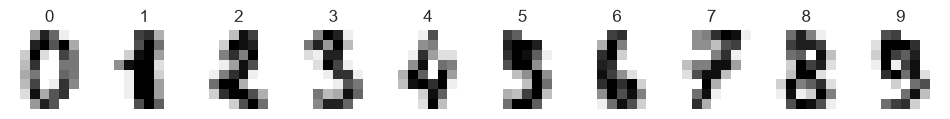

In [3]:
# The position of the first image of each digit: np.flatnonzero returns the positions where a condition holds
first_image_of_each_digit = [np.flatnonzero(digit_written == digit)[0] for digit in range(10)]

fig, axes = plt.subplots(1, 10, figsize=(12, 1.9))
for ax, image_position in zip(axes, first_image_of_each_digit):
    # reshape(8, 8) turns the 64 values back into a grid; cmap="gray_r" draws 0 white and 16 black
    ax.imshow(pixels.iloc[image_position].to_numpy().reshape(8, 8), cmap="gray_r")
    ax.set_title(digit_written.iloc[image_position])
    ax.axis("off")
plt.show()

**What do you see?** The images are coarse, but each digit is readable. Neighbouring pixels are strongly related: a stroke covers several of them at once. Related columns are what dimensionality reduction can compress.

The variance of each pixel shows how much it changes from image to image, and so how much information it can carry. `pixels.var()` returns one variance per column; we draw the 64 values on the 8 × 8 grid with `sns.heatmap`.

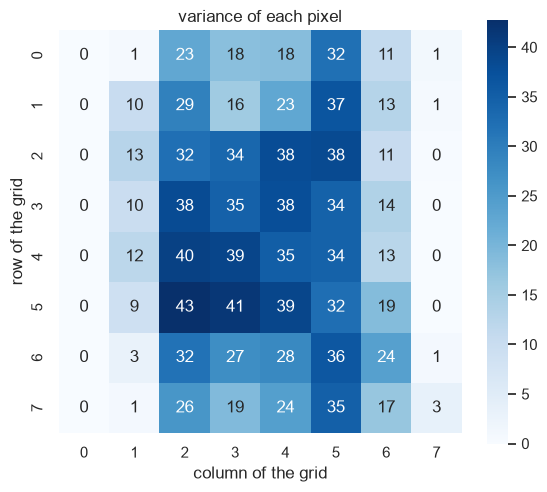

pixels with a variance below 1: 16 of 64


In [4]:
# One variance per pixel column, put back on the 8 × 8 grid
pixel_variance = pixels.var()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
# annot=True writes each value into its square, fmt=".0f" without decimals
sns.heatmap(pixel_variance.to_numpy().reshape(8, 8), annot=True, fmt=".0f", cmap="Blues", square=True, ax=ax)
ax.set_title("variance of each pixel")
ax.set_xlabel("column of the grid")
ax.set_ylabel("row of the grid")
plt.show()
# How many of the 64 pixels hardly change at all
print("pixels with a variance below 1:", (pixel_variance < 1).sum(), "of 64")

**What do you see?** The pixels in the middle of the grid change most, with variances up to 43. The left and right border columns hardly change: 16 of the 64 pixels have a variance below 1, and some are always 0 (white). These pixels carry almost no information, so a good reduction can ignore them.

## 4 Split the data

There is no target to hold out, but we still hold back a quarter of the images. The reduction is fitted on the training images only; the held-out images show whether it also works on digits it has not seen. `random_state=0` makes the split the same every time.

In [5]:
from sklearn.model_selection import train_test_split

# Keep 25% of the images as the held-out set; the digits are split along with the pixels
pixels_train, pixels_test, digit_train, digit_test = train_test_split(
    pixels, digit_written, test_size=0.25, random_state=0)
print(len(pixels_train), "training images,", len(pixels_test), "held-out images")

1347 training images, 450 held-out images


## 5 Process the data

All 64 columns are pixels on the same scale, 0 to 16, so we do **not** standardize them. `StandardScaler` would give every pixel a standard deviation of 1, also the border pixels that are almost always white. The plot shows what that does to two columns of the training images: `pixel_3_4`, in the middle where the strokes are, and `pixel_5_0`, at the left border.

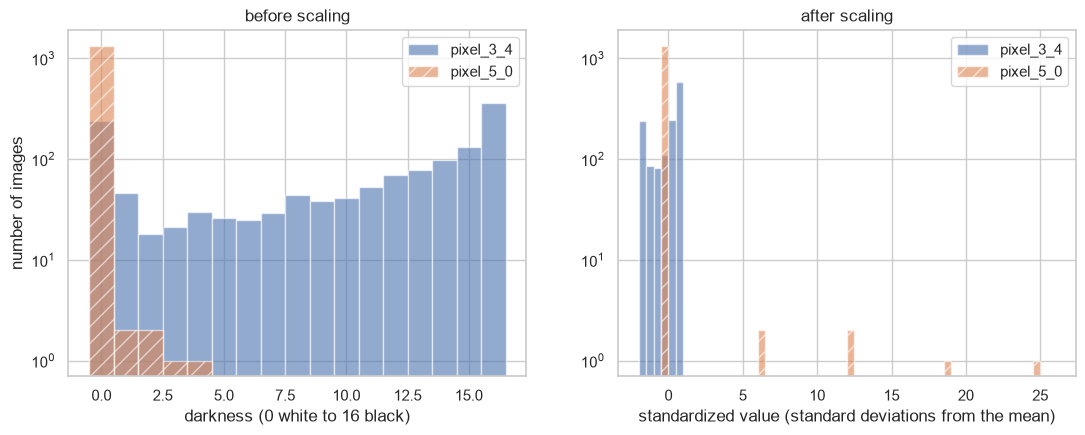

training images with pixel_5_0 = 0: 1341 of 1347
pixel_3_4     1.0
pixel_5_0    24.8
dtype: float64


In [6]:
from sklearn.preprocessing import StandardScaler

# fit_transform learns the mean and standard deviation of each column and returns the scaled array;
# pd.DataFrame puts it back into a table with the pixel names, so we can select columns by name
scaled_training_pixels = pd.DataFrame(StandardScaler().fit_transform(pixels_train), columns=pixels.columns)
shown_columns = ["pixel_3_4", "pixel_5_0"]

# Left: the raw values of two pixels; right: the same two pixels after scaling
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(13, 4.5))
# The same bins for both pixels in each panel: one bin per darkness level before, half a standard deviation after
bins_before = np.arange(-0.5, 17, 1)
bins_after = np.arange(-2, 26.5, 0.5)
for column, hatch in zip(shown_columns, ["", "//"]):
    ax_before.hist(pixels_train[column], bins=bins_before, alpha=0.6, hatch=hatch, label=column)
    ax_after.hist(scaled_training_pixels[column], bins=bins_after, alpha=0.6, hatch=hatch, label=column)
ax_before.set_title("before scaling")
ax_before.set_xlabel("darkness (0 white to 16 black)")
ax_before.set_ylabel("number of images")
ax_after.set_title("after scaling")
ax_after.set_xlabel("standardized value (standard deviations from the mean)")
for ax in (ax_before, ax_after):
    # A log scale on the y-axis shows the rare dark values of the border pixel next to the many zeros
    ax.set_yscale("log")
    ax.legend()
plt.show()
# How often the border pixel is white, and the largest scaled value of each of the two pixels
print("training images with pixel_5_0 = 0:", (pixels_train["pixel_5_0"] == 0).sum(), "of", len(pixels_train))
print(scaled_training_pixels[shown_columns].max().round(1))

**What do you see?** Before scaling, `pixel_3_4` uses the whole range from 0 to 16, while `pixel_5_0` is 0 in 1,341 of the 1,347 training images. After scaling, `pixel_3_4` lies between about −2 and 1 standard deviations. The few dark values of `pixel_5_0` become extreme: up to 24.8 standard deviations from its mean. Scaling would make a handful of stray dots at the border look as important as the strokes in the middle, so we keep the pixels as they are. For columns in different units (euros, metres, counts), scaling before PCA is needed; here all columns share one unit.

## 6 Run the pipeline

We start with the most common method, principal component analysis (PCA), with a first guess of 10 components. Then we choose the number of components with a stated rule, and finally we compare the two-dimensional map of PCA with a non-linear method, t-SNE. The five decisions of the two methods:

| Decision | PCA | t-SNE |
|---|---|---|
| Data | the 64 pixel values X of the training images; no target y | the 64 pixel values of the images to draw; no target y |
| Model | the mean image plus a weighted sum of k component images, at right angles to each other | two coordinates per image, learned for each image on its own |
| Loss function | the squared reconstruction error: how far each image is from its rebuilt version | how much the neighbours of each image in the map differ from its neighbours in pixel space (a Kullback–Leibler divergence) |
| Optimizer | a formula: the singular value decomposition of the centred data, exact and without iterations | gradient descent on the coordinates |
| Evaluation | the share of the pixel variance kept, the reconstruction error, and how well a classifier reads the digits from the k columns | the map itself: do images of the same digit lie together? |

Every number of components is scored in the same way on the held-out images. The scores answer the two questions of step 1:

- **Variance kept**: `transform` turns each image into k numbers, and `inverse_transform` rebuilds an image of 64 pixels from them. The share of variance kept is 1 minus the squared reconstruction error divided by the total squared distance of the images from the mean training image. 1 means nothing is lost.
- **Reconstruction error**: the root mean squared difference between the original and the rebuilt pixels, in darkness levels (0 to 16).
- **Reader accuracy**: the share of held-out digits that a classifier reads correctly from the k numbers. As the reader we use **5-nearest neighbours** (`KNeighborsClassifier(n_neighbors=5)`): it gives each image the most common digit of the 5 most similar training images. A `Pipeline` chains PCA and the reader. Only the reader sees the digits; PCA, the first step, ignores them.

The next cell computes the two values that every score uses: the total variance of the held-out images, and the first held-out image of each digit, which we draw next to its rebuilt version.

In [7]:
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# The mean training image, and the total squared distance of the held-out images from it: "all the variance"
mean_training_image = pixels_train.mean().to_numpy()
total_held_out_variance = ((pixels_test.to_numpy() - mean_training_image) ** 2).sum()
# The position of the first held-out image of each digit, for the pictures
first_held_out_of_each_digit = [np.flatnonzero(digit_test == digit)[0] for digit in range(10)]

### 6.1 PCA with 10 components

`PCA(n_components=10)` finds the 10 directions in pixel space along which the training images vary most. Each image is then described by 10 numbers, its position along these directions. We start with 10, a common first guess, and score it.

PCA, 10 components: variance kept 0.726, reconstruction error 2.27, reader accuracy 0.976


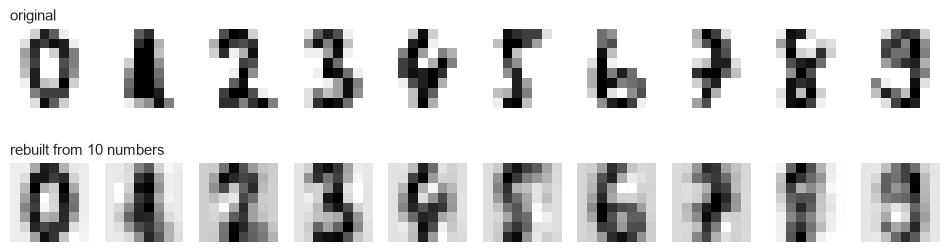

In [8]:
# The pipeline: PCA with 10 components, then the 5-nearest-neighbours reader on the 10 new columns
pca_10_pipeline = Pipeline([("pca", PCA(n_components=10)), ("knn", KNeighborsClassifier(n_neighbors=5))])
# fit learns the components from the training pixels and the reader from the training digits
pca_10_pipeline.fit(pixels_train, digit_train)
# named_steps["pca"] is the fitted PCA inside the pipeline
pca_10_pca = pca_10_pipeline.named_steps["pca"]

# Rebuild every held-out image from its numbers: transform, then inverse_transform
pca_10_rebuilt_images = pca_10_pca.inverse_transform(pca_10_pca.transform(pixels_test))
pca_10_squared_errors = (pixels_test.to_numpy() - pca_10_rebuilt_images) ** 2
pca_10_scores = {
    "reduction": "PCA, 10 components",
    "components": 10,
    # explained_variance_ratio_ holds the share of the training variance of each component
    "variance kept (training)": pca_10_pca.explained_variance_ratio_.sum(),
    "variance kept (held-out)": 1 - pca_10_squared_errors.sum() / total_held_out_variance,
    # The root of the mean squared difference per pixel, in darkness levels
    "reconstruction error": np.sqrt(pca_10_squared_errors.mean()),
    # score returns the share of held-out digits the reader gets right
    "reader accuracy": pca_10_pipeline.score(pixels_test, digit_test),
}
print(f"{pca_10_scores['reduction']}: variance kept {pca_10_scores['variance kept (held-out)']:.3f}, "
      f"reconstruction error {pca_10_scores['reconstruction error']:.2f}, "
      f"reader accuracy {pca_10_scores['reader accuracy']:.3f}")

# Top row: the first held-out image of each digit; bottom row: the same images rebuilt
fig, axes = plt.subplots(2, 10, figsize=(12, 3.2))
for column, image_position in enumerate(first_held_out_of_each_digit):
    axes[0, column].imshow(pixels_test.iloc[image_position].to_numpy().reshape(8, 8), cmap="gray_r")
    axes[1, column].imshow(pca_10_rebuilt_images[image_position].reshape(8, 8), cmap="gray_r")
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title("original", loc="left", fontsize=11)
axes[1, 0].set_title(f"rebuilt from {10} numbers", loc="left", fontsize=11)
plt.show()

**What do you see?** PCA with 10 components keeps 72.6% of the pixel variance of the held-out images. The rebuilt pixels differ from the originals by 2.27 darkness levels on average (RMSE), and the rebuilt images look blurred, with a grey background where the originals are white. Most digits are still readable by eye, and the reader recognizes 97.6% of the held-out digits from the 10 numbers.

What does a component mean? Each component is a direction in pixel space: one weight, its **loading**, per pixel. PCA rebuilds an image as the mean image plus a weighted sum of the component images. `components_` holds the loadings, one row per component, so we can draw each row as an 8 × 8 image. Red pixels have a positive loading, blue ones a negative loading. An image with a high value on the component is darker than the mean image in the red pixels and lighter in the blue ones.

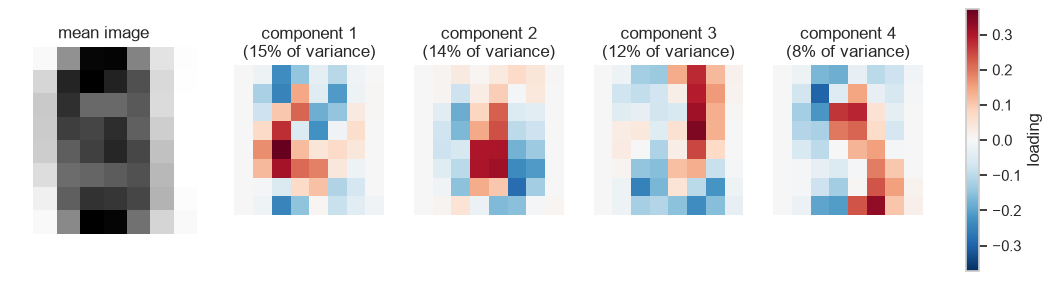

In [9]:
# The fitted PCA inside the pipeline: components_ has one row of 64 loadings per component
pca_10 = pca_10_pipeline.named_steps["pca"]
fig, axes = plt.subplots(1, 5, figsize=(14, 3.4))
# First panel: the mean image that every rebuilt image starts from
axes[0].imshow(pca_10.mean_.reshape(8, 8), cmap="gray_r")
axes[0].set_title("mean image")
# The other panels: the loadings of the first four components; the colour scale is symmetric around 0
largest_loading = np.abs(pca_10.components_[:4]).max()
for component, ax in enumerate(axes[1:]):
    loadings_image = ax.imshow(pca_10.components_[component].reshape(8, 8), cmap="RdBu_r",
                               vmin=-largest_loading, vmax=largest_loading)
    ax.set_title(f"component {component + 1}\n({pca_10.explained_variance_ratio_[component]:.0%} of variance)")
for ax in axes:
    ax.axis("off")
fig.colorbar(loadings_image, ax=axes[1:], label="loading")
plt.show()

**What do you see?** Every image starts from the mean image, a blurred mix of all digits. Some components read like strokes: component 2 (14% of the variance) is a vertical stroke in the middle of the lower half, with light sides, and component 3 (12%) is dark on the upper right and light along the bottom. Others, such as component 1 (15%), mix several parts of the grid and are hard to name. The border pixels have loadings near 0 in every component: PCA ignores them by itself, without any scaling.

### 6.2 Choose the number of components

The number of components is the **hyperparameter** of PCA: we choose it, PCA does not learn it. There is no target, so `GridSearchCV` does not fit. Instead we look at how much variance each component explains, the **scree plot**, and choose with a stated rule: **the smallest number of components that keeps at least 90% of the variance of the training images.** The rule uses the training images only, so the held-out images stay unseen until we score the choice.

`PCA()` without `n_components` keeps all 64 components. `np.cumsum` adds up the shares: its k-th value is the share kept by the first k components.

chosen number of components: 21 (keeps 0.905 of the training variance)


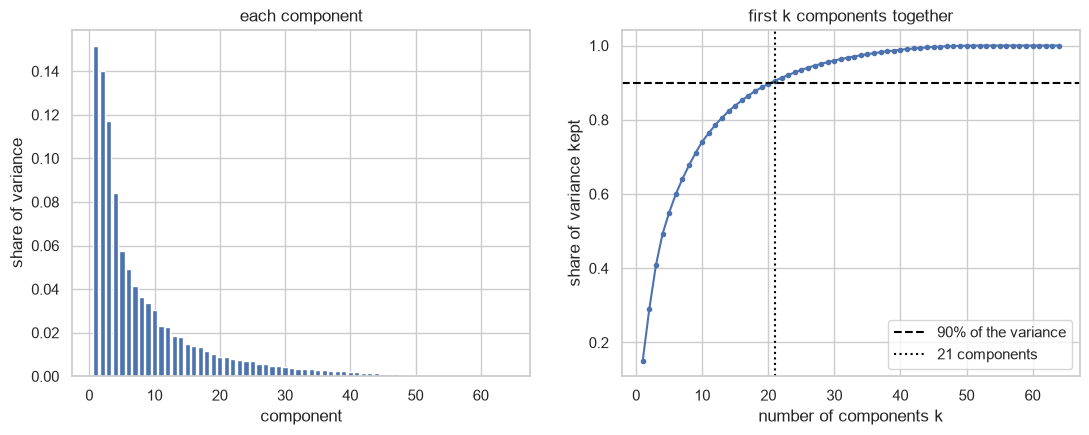

In [10]:
# All 64 components, fitted on the training images
full_pca = PCA().fit(pixels_train)
share_per_component = full_pca.explained_variance_ratio_
cumulative_share = np.cumsum(share_per_component)
# The rule: the first position where the cumulative share reaches 90%; +1 because positions start at 0
chosen_n_components = int(np.argmax(cumulative_share >= 0.90)) + 1
print("chosen number of components:", chosen_n_components,
      f"(keeps {cumulative_share[chosen_n_components - 1]:.3f} of the training variance)")

component_numbers = np.arange(1, 65)
fig, (ax_each, ax_cumulative) = plt.subplots(1, 2, figsize=(13, 4.5))
# Left: the share of each component, the scree plot
ax_each.bar(component_numbers, share_per_component)
ax_each.set_xlabel("component")
ax_each.set_ylabel("share of variance")
ax_each.set_title("each component")
# Right: the share kept by the first k components, with the 90% rule
ax_cumulative.plot(component_numbers, cumulative_share, marker=".")
ax_cumulative.axhline(0.90, color="black", linestyle="--", label="90% of the variance")
ax_cumulative.axvline(chosen_n_components, color="black", linestyle=":", label=f"{chosen_n_components} components")
ax_cumulative.set_xlabel("number of components k")
ax_cumulative.set_ylabel("share of variance kept")
ax_cumulative.set_title("first k components together")
ax_cumulative.legend()
plt.show()

**What do you see?** The first component explains 15% of the variance, and the shares fall quickly: after about 40 components, the rest add almost nothing. The cumulative share crosses 90% at **21 components**, which keep 90.5% of the training variance. So the rule chooses 21 components, a third of the 64 pixels.

To see what the rule costs and gains, we score every number of components from 1 to 64 on the held-out images, with the same steps as in 6.1 but without the pictures. A `for` loop collects one row of scores per number of components, and we plot the three scores against the number of components.

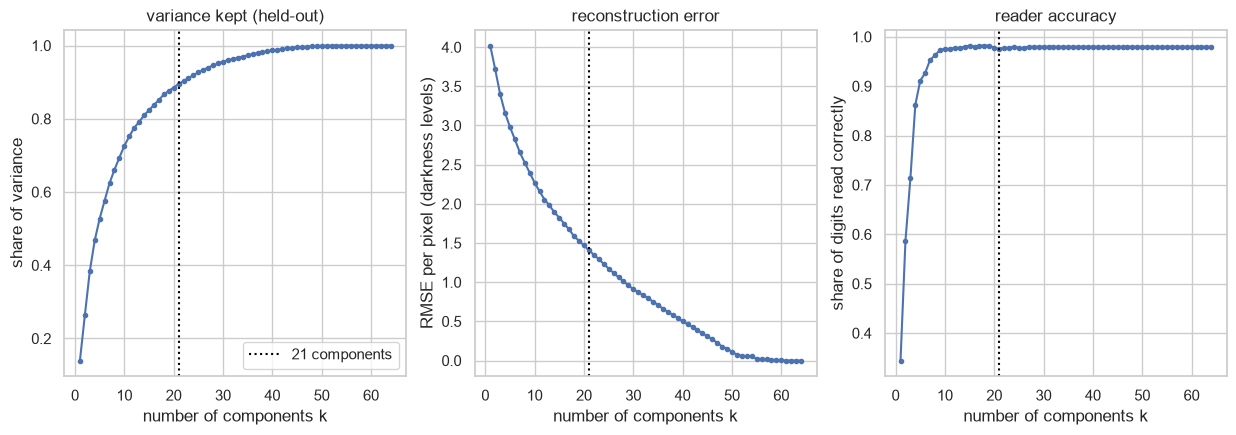

In [11]:
# One row of scores per number of components, collected in a list
score_rows = []
for n_components in component_numbers:
    # The same pipeline as in 6.1, with n_components components
    loop_pipeline = Pipeline([("pca", PCA(n_components=n_components)), ("knn", KNeighborsClassifier(n_neighbors=5))])
    loop_pipeline.fit(pixels_train, digit_train)
    loop_pca = loop_pipeline.named_steps["pca"]
    # Rebuild the held-out images and compare them with the originals
    loop_squared_errors = (pixels_test.to_numpy() - loop_pca.inverse_transform(loop_pca.transform(pixels_test))) ** 2
    score_rows.append({
        "components": n_components,
        "variance kept (held-out)": 1 - loop_squared_errors.sum() / total_held_out_variance,
        "reconstruction error": np.sqrt(loop_squared_errors.mean()),
        "reader accuracy": loop_pipeline.score(pixels_test, digit_test),
    })
all_component_scores = pd.DataFrame(score_rows).set_index("components")

score_columns = ["variance kept (held-out)", "reconstruction error", "reader accuracy"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, score_name in zip(axes, score_columns):
    ax.plot(all_component_scores.index, all_component_scores[score_name], marker=".")
    # The dotted line marks the number of components the rule chose
    ax.axvline(chosen_n_components, color="black", linestyle=":", label=f"{chosen_n_components} components")
    ax.set_xlabel("number of components k")
    ax.set_title(score_name)
axes[0].set_ylabel("share of variance")
axes[1].set_ylabel("RMSE per pixel (darkness levels)")
axes[2].set_ylabel("share of digits read correctly")
axes[0].legend()
plt.show()

**What do you see?** On the held-out images, the variance kept follows the training curve: 89.5% at 21 components. The reconstruction error falls steadily, from 4.0 darkness levels with one component to 1.41 with 21, and to 0 with all 64. The reader is different: its accuracy rises steeply up to about 10 components (97.6%) and then stays flat near 98%. Reading digits needs fewer numbers than rebuilding images. The 90% rule answers the question "how much of the image do we keep?"; a team that only wants the reader could choose fewer components.

We score the chosen number of components in the same way as the first guess in 6.1: the same steps, with `chosen_n_components` from the rule above.

PCA, 21 components: variance kept 0.895, reconstruction error 1.41, reader accuracy 0.976


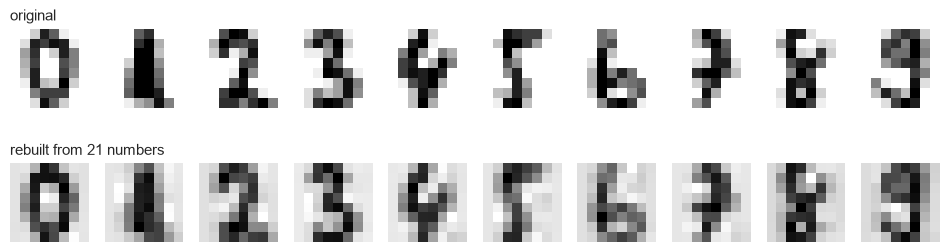

In [12]:
# The same pipeline as in 6.1, with the number of components chosen by the 90% rule
chosen_pipeline = Pipeline([("pca", PCA(n_components=chosen_n_components)), ("knn", KNeighborsClassifier(n_neighbors=5))])
# fit learns the components from the training pixels and the reader from the training digits
chosen_pipeline.fit(pixels_train, digit_train)
# named_steps["pca"] is the fitted PCA inside the pipeline
chosen_pca = chosen_pipeline.named_steps["pca"]

# Rebuild every held-out image from its numbers: transform, then inverse_transform
chosen_rebuilt_images = chosen_pca.inverse_transform(chosen_pca.transform(pixels_test))
chosen_squared_errors = (pixels_test.to_numpy() - chosen_rebuilt_images) ** 2
chosen_scores = {
    "reduction": f"PCA, {chosen_n_components} components",
    "components": chosen_n_components,
    # explained_variance_ratio_ holds the share of the training variance of each component
    "variance kept (training)": chosen_pca.explained_variance_ratio_.sum(),
    "variance kept (held-out)": 1 - chosen_squared_errors.sum() / total_held_out_variance,
    # The root of the mean squared difference per pixel, in darkness levels
    "reconstruction error": np.sqrt(chosen_squared_errors.mean()),
    # score returns the share of held-out digits the reader gets right
    "reader accuracy": chosen_pipeline.score(pixels_test, digit_test),
}
print(f"{chosen_scores['reduction']}: variance kept {chosen_scores['variance kept (held-out)']:.3f}, "
      f"reconstruction error {chosen_scores['reconstruction error']:.2f}, "
      f"reader accuracy {chosen_scores['reader accuracy']:.3f}")

# Top row: the first held-out image of each digit; bottom row: the same images rebuilt
fig, axes = plt.subplots(2, 10, figsize=(12, 3.2))
for column, image_position in enumerate(first_held_out_of_each_digit):
    axes[0, column].imshow(pixels_test.iloc[image_position].to_numpy().reshape(8, 8), cmap="gray_r")
    axes[1, column].imshow(chosen_rebuilt_images[image_position].reshape(8, 8), cmap="gray_r")
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_title("original", loc="left", fontsize=11)
axes[1, 0].set_title(f"rebuilt from {chosen_n_components} numbers", loc="left", fontsize=11)
plt.show()

**What do you see?** With 21 components, the variance kept on the held-out images rises from 72.6% to 89.5%, and the reconstruction error falls from 2.27 to 1.41 darkness levels. The rebuilt images are sharper: the 4, the 5 and the 8 now look like their originals. The reader accuracy stays at 97.6%, the same as with 10 components.

For the first question we also need the reader on all 64 pixels, without any reduction: it shows how much the reduction costs. The pipeline has the reader step only.

In [13]:
# The same 5-nearest-neighbours reader, on all 64 pixels
pixel_reader = Pipeline([("knn", KNeighborsClassifier(n_neighbors=5))]).fit(pixels_train, digit_train)
pixel_reader_accuracy = pixel_reader.score(pixels_test, digit_test)
print(f"reader on all 64 pixels: accuracy {pixel_reader_accuracy:.3f}")

reader on all 64 pixels: accuracy 0.980


### 6.3 A map in two numbers: PCA and t-SNE

For the second question, the map, we need two numbers per image. PCA with 2 components keeps the two directions of largest variance. **t-SNE** (t-distributed stochastic neighbour embedding; van der Maaten and Hinton, 2008) is non-linear: it places the images so that images that are close in pixel space stay close on the map. t-SNE has no `transform` for new images, so `fit_transform` learns the map of the held-out images directly. `perplexity=30` sets about how many neighbours each image keeps in view; `random_state=0` fixes its random start.

Both maps show the held-out images. The colour is the digit written, used only to read the maps: neither method sees it. A `for` loop draws the two maps, one panel each.

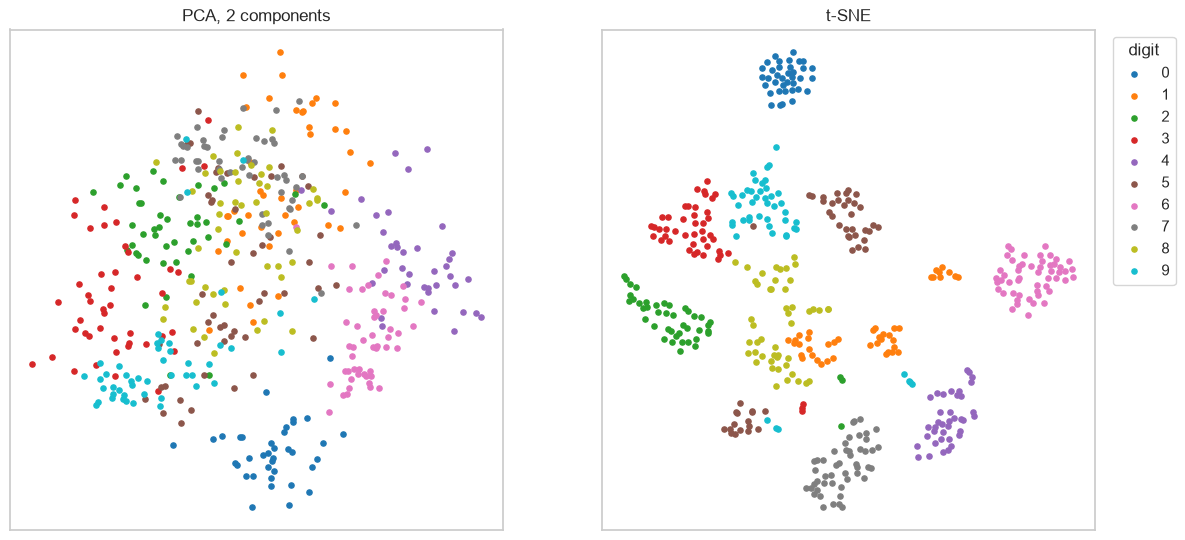

In [14]:
from sklearn.manifold import TSNE

# PCA: fitted on the training images, then applied to the held-out images
pca_map_points = PCA(n_components=2).fit(pixels_train).transform(pixels_test)
# t-SNE: learns two coordinates for every held-out image
tsne_map_points = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(pixels_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, map_points, title in zip(axes, [pca_map_points, tsne_map_points], ["PCA, 2 components", "t-SNE"]):
    # One colour per digit: tab10 gives ten distinct colours
    for digit in range(10):
        is_digit = (digit_test == digit).to_numpy()
        ax.scatter(map_points[is_digit, 0], map_points[is_digit, 1], s=14, color=plt.cm.tab10(digit), label=str(digit))
    ax.set_title(title)
    # The coordinates of a map have no unit, so we hide the tick labels
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(title="digit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**What do you see?** On the PCA map, the 0s (bottom), the 4s and 6s (right) and the 3s (left) form their own regions, but the 1s, 5s, 7s and 8s pile up in the middle. Two straight directions keep only about 29% of the variance, too little to separate ten digits. t-SNE separates almost every digit into its own group, with only a few images in the wrong group. The 1s are split into several small groups, and some 8s lie next to 1s. Read a t-SNE map with care: the groups are meaningful, but the distances between groups and the sizes of the groups are not.

A third component adds depth. Plotly draws an **interactive** 3D map of the held-out images on PCA with 3 components: drag to turn it, scroll to zoom, and hover over a point to read its digit and its position in the held-out set. Click a digit in the legend to hide or show it. `px.scatter_3d` takes a DataFrame and the names of the columns for the three axes and the colour.

In [15]:
import plotly.express as px
import plotly.io as pio

# Save the figure in the notebook in two forms: for JupyterLab and VS Code, and as HTML that loads plotly from the web
pio.renderers.default = "plotly_mimetype+notebook_connected"

# Three numbers per held-out image: PCA with 3 components, fitted on the training images
pca_3d_points = PCA(n_components=3).fit(pixels_train).transform(pixels_test)
map_table = pd.DataFrame(pca_3d_points, columns=["component 1", "component 2", "component 3"])
# The digit as text, so plotly gives each digit its own colour instead of a colour scale
map_table["digit"] = digit_test.astype(str).to_numpy()
map_table["held-out image"] = np.arange(len(map_table))

# category_orders sorts the legend 0 to 9; hover_data adds the image position to the hover box
figure_3d = px.scatter_3d(map_table, x="component 1", y="component 2", z="component 3", color="digit",
                          category_orders={"digit": [str(digit) for digit in range(10)]},
                          hover_data=["held-out image"], title="PCA, 3 components: held-out images",
                          width=800, height=600)
figure_3d.update_traces(marker_size=3)
figure_3d.show()
# The reader accuracy from 2 and from 3 components, from the scores of 6.2
print("reader accuracy from 2 and from 3 components:", all_component_scores.loc[[2, 3], "reader accuracy"].round(3).tolist())

reader accuracy from 2 and from 3 components: [0.587, 0.713]


**What do you see?** Turn the map and look at the digits that overlap in the middle of the flat PCA map. The reader gives a number for what a third direction adds: it recognizes 58.7% of the held-out digits from 2 components and 71.3% from 3. A third straight direction helps, but PCA needs many more components to keep all ten digits apart: with 10 components the reader reaches 97.6%.

## 7 Report the results

One table puts the two PCA settings of 6.1 and 6.2 and the reader on all 64 pixels side by side, in the order we built them. Then we ask how sure these numbers are. The maps of 6.3 have no score; we compare them by eye.

In [16]:
# The reader on all 64 pixels keeps all the variance and rebuilds nothing, so its error is 0
pixel_scores = {"reduction": "all 64 pixels", "components": 64, "variance kept (training)": 1.0,
                "variance kept (held-out)": 1.0, "reconstruction error": 0.0, "reader accuracy": pixel_reader_accuracy}
# One row per setting, built from the score dictionaries of 6.1 and 6.2
test_results = pd.DataFrame([pca_10_scores, chosen_scores, pixel_scores]).set_index("reduction").round(3)
test_results

,components,variance kept (training),variance kept (held-out),reconstruction error,reader accuracy
reduction,,,,,
"PCA, 10 components",10,0.741,0.726,2.268,0.976
"PCA, 21 components",21,0.905,0.895,1.405,0.976
all 64 pixels,64,1.000,1.000,0.000,0.980


### 7.1 How sure is each score?

The images are one sample of digits. Another sample would give slightly different numbers. A **95% confidence interval** shows how far a number could move for that reason: over many samples, 95 of 100 such intervals contain the true value.

**The share of variance, by the bootstrap.** The share of variance that k components explain has no simple formula for its interval, so we use the **bootstrap**:

1. Draw as many training images as there are, **with replacement**: some images appear twice, some not at all.
2. Fit PCA again on these images and record the share of variance kept by the first 10 and by the first 21 components.
3. Repeat 1,000 times. The middle 95% of the 1,000 shares, from the 2.5th to the 97.5th percentile, is the interval.

For a model that predicts, the bootstrap keeps the fitted model fixed and resamples the test rows. Here we refit PCA on every resample, because the components are what we estimate: the uncertainty we ask about is how much the components and their shares change with another sample of images. `rng.integers(0, n, size=(1000, n))` draws the row positions of all 1,000 resamples at once, one resample per row of the array.

In [17]:
# 1,000 resamples of the training images; each row of resampled_training_rows holds the positions of one resample
rng = np.random.default_rng(0)
n_resamples = 1000
training_images = pixels_train.to_numpy()
n_training_rows = len(training_images)
resampled_training_rows = rng.integers(0, n_training_rows, size=(n_resamples, n_training_rows))

# Refit PCA with all 64 components on every resample and keep its cumulative shares (one row per resample)
bootstrap_cumulative_share = np.array([np.cumsum(PCA().fit(training_images[rows]).explained_variance_ratio_)
                                       for rows in resampled_training_rows])
# The share kept by k components is in column k - 1
bootstrap_share = {n: bootstrap_cumulative_share[:, n - 1] for n in [10, chosen_n_components]}

interval_rows = []
for n, shares in bootstrap_share.items():
    lower, upper = np.percentile(shares, [2.5, 97.5])
    interval_rows.append({"components": n, "share of variance": cumulative_share[n - 1],
                          "95% CI from": lower, "95% CI to": upper})
variance_intervals = pd.DataFrame(interval_rows).set_index("components").round(3)
variance_intervals

,share of variance,95% CI from,95% CI to
components,,,
10,0.741,0.739,0.749
21,0.905,0.905,0.910


**What do you see?** Both intervals are narrow, under one percentage point: with 1,347 images, the share of variance that PCA finds hardly depends on which images are in the sample. The intervals are not centred on the share: 0.741 lies at the lower end of 0.739 to 0.749. A resample repeats some images and leaves out others, so it holds fewer different images, and PCA on fewer images finds the first components a little stronger than they are. The bootstrap of a PCA share therefore leans slightly upwards; the share itself is the better estimate.

**The reader accuracy, by the Wilson interval.** Accuracy is a share: correct digits out of 450 held-out images. The usual formula, the share plus or minus 1.96 standard errors, assumes a bell-shaped (normal) curve, and that needs about 10 of each outcome, here 10 correct and 10 wrong digits. The **Wilson interval** does not need the bell shape, so we use it. `proportion_confint(count, total, method="wilson")` from statsmodels computes it. The fitted readers stay fixed.

In [18]:
from statsmodels.stats.proportion import proportion_confint

# The three fitted readers, and for each the held-out images it reads correctly (True or False)
fitted_readers = {
    "PCA, 10 components": pca_10_pipeline,
    f"PCA, {chosen_n_components} components": chosen_pipeline,
    "all 64 pixels": pixel_reader,
}
true_digits = digit_test.to_numpy()
is_read_correctly = {name: reader.predict(pixels_test) == true_digits for name, reader in fitted_readers.items()}

n_test_rows = len(true_digits)
accuracy_rows = []
for name, correct in is_read_correctly.items():
    n_correct = int(correct.sum())
    lower, upper = proportion_confint(n_correct, n_test_rows, method="wilson")
    accuracy_rows.append({"reader": name, "correct": n_correct, "wrong": n_test_rows - n_correct,
                          "accuracy": n_correct / n_test_rows, "95% CI from": lower, "95% CI to": upper})
accuracy_intervals = pd.DataFrame(accuracy_rows).set_index("reader").round(3)
accuracy_intervals

,correct,wrong,accuracy,95% CI from,95% CI to
reader,,,,,
"PCA, 10 components",439,11,0.976,0.957,0.986
"PCA, 21 components",439,11,0.976,0.957,0.986
all 64 pixels,441,9,0.980,0.962,0.989


**What do you see?** Both PCA readers read 439 of the 450 held-out digits correctly (accuracy 0.976, 95% interval 0.957 to 0.986), and the reader on all 64 pixels reads 441 (0.980, 0.962 to 0.989). The three intervals overlap almost completely. Each is about 3 percentage points wide: with 450 images, one digit more or less moves the accuracy by 0.002.

### 7.2 Is the difference real? The interval of the difference

To compare two settings, we do not compare their two intervals. The intervals of the readers in 7.1 overlap almost completely. Many people read this as "the readers are equally good", but that is a common mistake. A comparison of two classmates shows why.

> Anna and Ben take the same exam every year, and the exam is harder in some years than in others. Anna's scores range from 70 to 90, and Ben's from 75 to 95, so the ranges overlap. But in every year, on the same exam, Ben scores about 5 points more than Anna. Is Ben better? Yes. The overlap only shows that the exams vary in difficulty. To compare them, you compare them on the same exam, which is the difference.

Both settings are scored on the **same** rows: the two shares of variance come from the same PCA fit on the same resampled images, and the two readers read the same held-out images. When a resample happens to hold many easy images, both do well; when it holds many hard ones, both do worse. Most of the width of each interval comes from this shared luck, and it cancels when we subtract one score from the other.

So we compute the **difference** on every resample, with the same rows for both, and take the middle 95% of the 1,000 differences: the **95% interval of the difference**.

- the interval lies above 0: the first setting is ahead, by about the amount the interval shows;
- the interval contains 0: on this data we cannot tell the two settings apart.

For the readers, the readers stay fixed and we resample the 450 held-out images, as in the other end-to-end notebooks.

In [19]:
# Share of variance: chosen number of components minus 10 components, on the same 1,000 PCA fits
variance_differences = bootstrap_share[chosen_n_components] - bootstrap_share[10]

# Reader accuracy: 1,000 resamples of the held-out images, the same rows for both readers
resampled_test_rows = rng.integers(0, n_test_rows, size=(n_resamples, n_test_rows))
chosen_name = f"PCA, {chosen_n_components} components"
# correct[rows] picks the resampled images; .mean(axis=1) gives one accuracy per resample
accuracy_differences = (is_read_correctly[chosen_name][resampled_test_rows].mean(axis=1)
                        - is_read_correctly["all 64 pixels"][resampled_test_rows].mean(axis=1))

# Each comparison: (label, difference on the original rows, the 1,000 resampled differences)
comparisons = {
    f"share of variance: {chosen_n_components} minus 10 components": (
        cumulative_share[chosen_n_components - 1] - cumulative_share[9], variance_differences),
    f"reader accuracy: {chosen_n_components} components minus all 64 pixels": (
        accuracy_intervals.loc[chosen_name, "accuracy"] - accuracy_intervals.loc["all 64 pixels", "accuracy"],
        accuracy_differences),
}
difference_rows = []
for label, (difference, resampled_differences) in comparisons.items():
    lower, upper = np.percentile(resampled_differences, [2.5, 97.5])
    difference_rows.append({"comparison": label, "difference": difference, "95% CI from": lower, "95% CI to": upper})
# On how many held-out images only one of the two readers is right
only_pixels_right = int((is_read_correctly["all 64 pixels"] & ~is_read_correctly[chosen_name]).sum())
only_chosen_right = int((is_read_correctly[chosen_name] & ~is_read_correctly["all 64 pixels"]).sum())
print("images read correctly only on all 64 pixels:", only_pixels_right, "| only on the components:", only_chosen_right)
difference_intervals = pd.DataFrame(difference_rows).set_index("comparison").round(3)
difference_intervals

images read correctly only on all 64 pixels: 2 | only on the components: 0


,difference,95% CI from,95% CI to
comparison,,,
share of variance: 21 minus 10 components,0.164,0.159,0.168
reader accuracy: 21 components minus all 64 pixels,-0.004,-0.013,0.000


A histogram of the 1,000 differences of each comparison shows the same thing as a picture. The solid lines mark the 95% interval, the dashed line a difference of 0, "no difference". An accuracy on 450 images moves in steps of one image, 1/450, so the right histogram gets one bar per step.

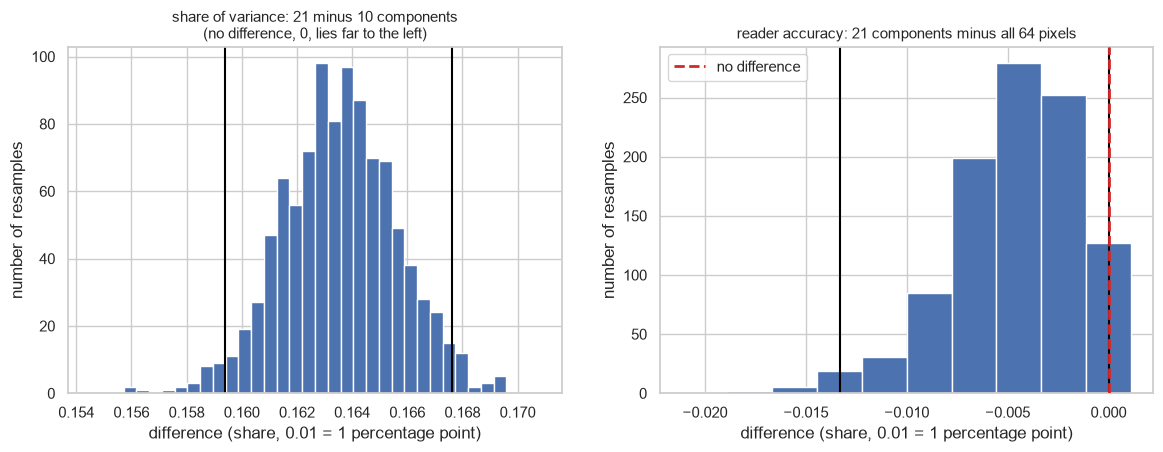

In [20]:
# Bins: 30 equal bins for the share of variance; for the accuracy one bar per step of 1/450,
# with the bar edges half a step on either side of each possible value
accuracy_steps = np.round(accuracy_differences * n_test_rows)
bins_per_comparison = [30, (np.arange(accuracy_steps.min(), accuracy_steps.max() + 2) - 0.5) / n_test_rows]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (label, (difference, resampled_differences)), bins in zip(axes, comparisons.items(), bins_per_comparison):
    ax.hist(resampled_differences, bins=bins)
    # The 95% interval as two solid lines, the value 0 as a dashed line
    for bound in np.percentile(resampled_differences, [2.5, 97.5]):
        ax.axvline(bound, color="black")
    # zorder=3 draws the dashed line on top, in case it lies on an end of the interval
    ax.axvline(0, color="tab:red", linestyle="--", linewidth=2, zorder=3, label="no difference")
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("difference (share, 0.01 = 1 percentage point)")
    ax.set_ylabel("number of resamples")
axes[1].legend()
# The share-of-variance differences lie far from 0: show them up close, and say where 0 is
axes[0].set_xlim(variance_differences.min() - 0.002, variance_differences.max() + 0.002)
axes[0].set_title(f"{axes[0].get_title()}\n(no difference, 0, lies far to the left)", fontsize=11)
plt.show()

**What do you see?** Left: 21 components keep 16.4 percentage points more of the training variance than 10 components (95% interval of the difference 15.9 to 16.8). The interval lies far above 0, so the gain is real. Right: the reader on 21 components reads 0.4 percentage points fewer digits than the reader on all 64 pixels (95% interval −1.3 to 0.0). The two readers disagree on 2 of the 450 images only, and on both the reader on all pixels is right. In the resamples that leave out both images, the difference is exactly 0, so the upper end of the interval is 0. The interval contains 0: on these 450 images we cannot tell the reader on 21 numbers from the reader on 64. At worst, the reduction costs about one digit in a hundred.

**One assumption to check.** The bootstrap treats every image as an independent draw. But the 1,797 images were written by only 13 people, so many images share the handwriting of one person and are not fully independent. The intervals above are therefore somewhat too narrow. Resampling whole writers instead of images would widen them, but the data do not say who wrote which image. For the Wilson interval, the normal approximation would need about 10 wrong digits per reader; the readers make 9 and 11 wrong readings, right at that limit, which is why we use the Wilson interval.

### 7.3 Use the model on a new input

If the postal service uses the reduction, every new scan goes through it. A new scan arrives as one row of 64 pixel values, from 0 (white) to 16 (black). The fitted `chosen_pipeline` of 6.2 holds two steps. `transform` of its PCA step (`chosen_pca`) turns the 64 pixels into the 21 numbers, and `predict` of its reader step, the 5-nearest-neighbours classifier, turns the 21 numbers into a digit. Nothing is refitted.

the new input: (1, 64) (one image, 64 pixels)
[[ 0.  0. 11. 16. 15.  3.  0.  0.]
 [ 0.  5. 16. 12. 11. 13.  0.  0.]
 [ 0.  3. 13.  1.  5. 15.  0.  0.]
 [ 0.  0.  0.  0. 12. 11.  0.  0.]
 [ 0.  0.  0.  1. 16.  7.  0.  0.]
 [ 0.  0.  0. 10. 15.  0.  0.  0.]
 [ 0.  0. 12. 16. 16. 11.  1.  0.]
 [ 0.  0. 13. 13.  8. 13. 16.  8.]]

PCA transform: (1, 64) → (1, 21)
[[-16.43   6.32  -3.    -5.72   8.24   0.28 -18.83   5.81   1.9    8.55
   -3.77  -2.02  -5.05   6.18   5.97  -4.71   0.03   3.39   6.68  -5.5
   -0.35]]

reader predict returns: [2]
digit written on the scan: 2
the reader reads this scan as the digit 2


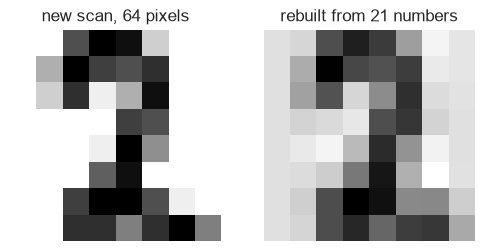

In [21]:
# We have no new scan, and 64 pixel values cannot be made up by hand in a realistic way.
# So we treat held-out image 0 as if it had just been scanned: the pipeline never saw it.
# pixels_test.iloc[[0]] returns a DataFrame with one row and all 64 pixel columns
new_digit = pixels_test.iloc[[0]]
print("the new input:", new_digit.shape, "(one image, 64 pixels)")
# reshape(8, 8) prints all 64 values as the 8 x 8 grid of the scan
print(new_digit.to_numpy().reshape(8, 8))

# transform of the fitted PCA: 64 pixels in, 21 numbers out
new_digit_components = chosen_pca.transform(new_digit)
print("\nPCA transform:", new_digit.shape, "→", new_digit_components.shape)
print(new_digit_components.round(2))

# predict of the fitted reader, the last step of the pipeline: 21 numbers in, one digit out
y_predicted_knn = chosen_pipeline.named_steps["knn"].predict(new_digit_components)
print("\nreader predict returns:", y_predicted_knn)
# The digit that was written; we know it because the image is a held-out one
print("digit written on the scan:", digit_test.iloc[0])
print(f"the reader reads this scan as the digit {y_predicted_knn[0]}")

# Left: the scan as the reader gets it; right: the image rebuilt from its 21 numbers
fig, (ax_scan, ax_rebuilt) = plt.subplots(1, 2, figsize=(6, 3.2))
ax_scan.imshow(new_digit.to_numpy().reshape(8, 8), cmap="gray_r")
ax_scan.set_title("new scan, 64 pixels")
ax_rebuilt.imshow(chosen_pca.inverse_transform(new_digit_components).reshape(8, 8), cmap="gray_r")
ax_rebuilt.set_title(f"rebuilt from {chosen_n_components} numbers")
for ax in (ax_scan, ax_rebuilt):
    ax.axis("off")
plt.show()

**What do you see?** The input is one row of 64 pixels, printed above as the 8 × 8 grid; the image shows a 2. PCA `transform` turns it into 21 numbers: the shape changes from (1, 64) to (1, 21). The first two are −16.43 and 6.32, the position of the scan along the first two components. The reader's `predict` returns `[2]`, and the digit written on the scan is 2, so the reading is correct. The image rebuilt from the 21 numbers is blurred, with a grey background, but it is still clearly a 2. A deployed system sends only these 21 numbers to the reader, a third of the 64 pixels.

**Finding.** PCA with 21 components, chosen by the rule of 90% of the training variance, keeps 90.5% of the variance of the training images (95% bootstrap interval 90.5% to 91.0%) and 89.5% on the held-out images, and a 5-nearest-neighbours reader recognizes 97.6% of the held-out digits from these 21 numbers (95% Wilson interval 95.7% to 98.6%). Against the reader on all 64 pixels, the difference is −0.4 percentage points (95% interval of the difference −1.3 to 0.0), so on these images the reduction to a third of the numbers costs no measurable accuracy, while 21 components keep 16.4 points more variance than 10 (95% interval 15.9 to 16.8) and give sharper rebuilt images. One limitation: the images come from only 13 writers, so the intervals are somewhat too narrow, and PCA is linear, so its two-component map separates the digits poorly, where t-SNE and UMAP draw clear groups.

## 8 A recent method

**UMAP** (uniform manifold approximation and projection; McInnes, Healy and Melville, Tutte Institute, 2018) is a newer non-linear method for maps. Like t-SNE it keeps the nearest neighbours of each image close, but it is faster on large data, and it has a `transform` for new images. It lives in the package `umap-learn` and follows the scikit-learn pattern: `fit` on the training images, `transform` the held-out ones. `n_neighbors=15` sets how many neighbours each image keeps in view; `random_state=0` fixes its random start (and makes it run on one core). We draw its map of the held-out images next to the t-SNE map of 6.3 (`tsne_map_points`), in the same way as there, and compare them by eye.

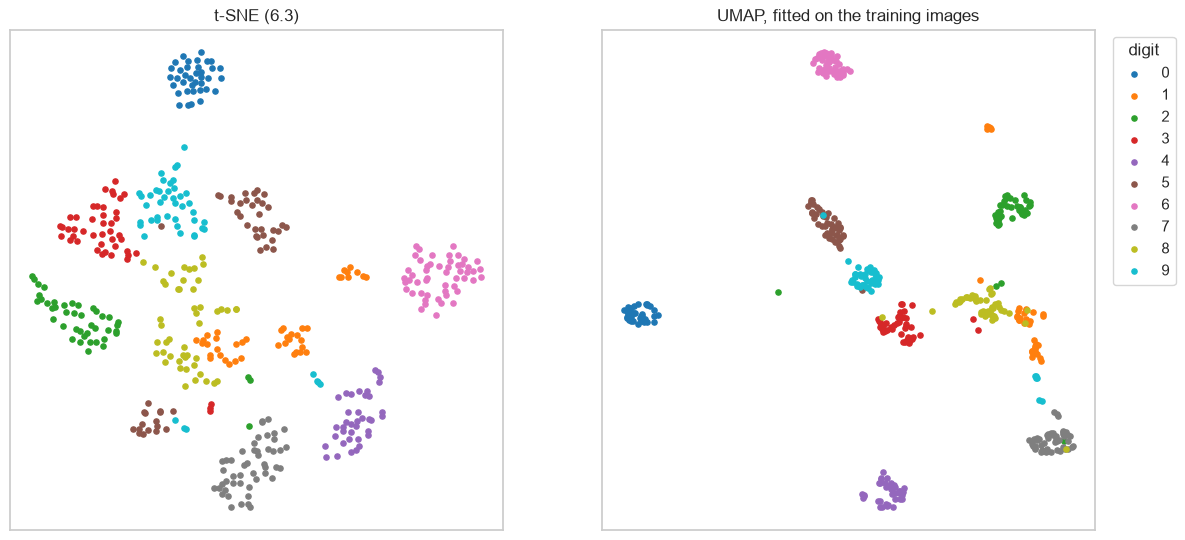

In [22]:
import warnings

# Hide two notices that do not affect the result: a display helper that is not installed,
# and the note that random_state makes UMAP run on one core
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", message=".*overridden to 1 by setting random_state.*")
import umap

# fit learns the map from the training images; transform places the held-out images on it
umap_reducer = umap.UMAP(n_components=2, n_neighbors=15, random_state=0).fit(pixels_train)
umap_map_points = umap_reducer.transform(pixels_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, map_points, title in zip(axes, [tsne_map_points, umap_map_points], ["t-SNE (6.3)", "UMAP, fitted on the training images"]):
    # One colour per digit: tab10 gives ten distinct colours
    for digit in range(10):
        is_digit = (digit_test == digit).to_numpy()
        ax.scatter(map_points[is_digit, 0], map_points[is_digit, 1], s=14, color=plt.cm.tab10(digit), label=str(digit))
    ax.set_title(title)
    # The coordinates of a map have no unit, so we hide the tick labels
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(title="digit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**What do you see?** UMAP also separates almost every digit into its own group, and its groups are tighter than those of t-SNE, with more empty space between them. As in t-SNE, the 1s are split into parts, and some lie in a chain next to the 8s and the 7s. The main practical difference is that UMAP learned its map from the training images and placed the held-out images on it with `transform`; t-SNE had to learn a new map from the held-out images themselves. As with t-SNE, the distances between the groups have no clear meaning.

> 📖 **Read more:** [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/how_umap_works.html) (McInnes and colleagues): how UMAP builds its map, and how to read its parameters.